# Sleeves

One key component of the entire system is sleeves. These are certain assets which are held according to current market conditions. I will show in this notebook the effect they have together. These assets are not in the core since they do not necessarily perform well over the entire period, but primarily concentrated into certain market conditions.

In [ ]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## Contribution to the core

Lets begin with a table showcasing key statistics about the sleeves.

In [2]:
sp.table("parts_stats.csv").query("part == 'sleeves'").drop(columns="part").set_index("window")

,months,mean_pp_per_year,vol_pp_per_year,sharpe_of_contribution,best_month_pp,worst_month_pp,sum_pp,correlation_with_core
window,,,,,,,,
full 2001-02–2026-09,308,2.974,7.264,0.409,10.166,-9.736,76.343,-0.323
book 2006-01–2026-09,249,3.479,8.008,0.434,10.166,-9.736,72.193,-0.373
2001-05,59,0.844,2.141,0.394,1.605,-1.860,4.149,-0.070
2006-13,96,4.800,8.074,0.594,8.525,-3.907,38.400,-0.231
2014-19,72,-0.570,5.511,-0.103,5.934,-4.457,-3.418,-0.392
2020-26,81,5.513,9.627,0.573,10.166,-9.736,37.212,-0.534


The returns percentages are all relative to the core. Firstly notice that (combined), all sleeves have negative correlation with the core. This is important to me, since diversifying across assets is one thing that tends to perform well in positive market times, with the defensive basket protecting us otherwise. Moreover, notice the additional Sharpe contribution is positive in every time period apart from 2014-2019, where (combined), the sleeves reduce Sharpe slightly due to it being the strongest era for the core. In practice, looking at the last table in the notebook, the sleeves infact increases the Sharpe of the whole book, since they cut more risk than return.

## All sleeves combined

The following equity sleeve shows the approximate path of combined sleeves over time.

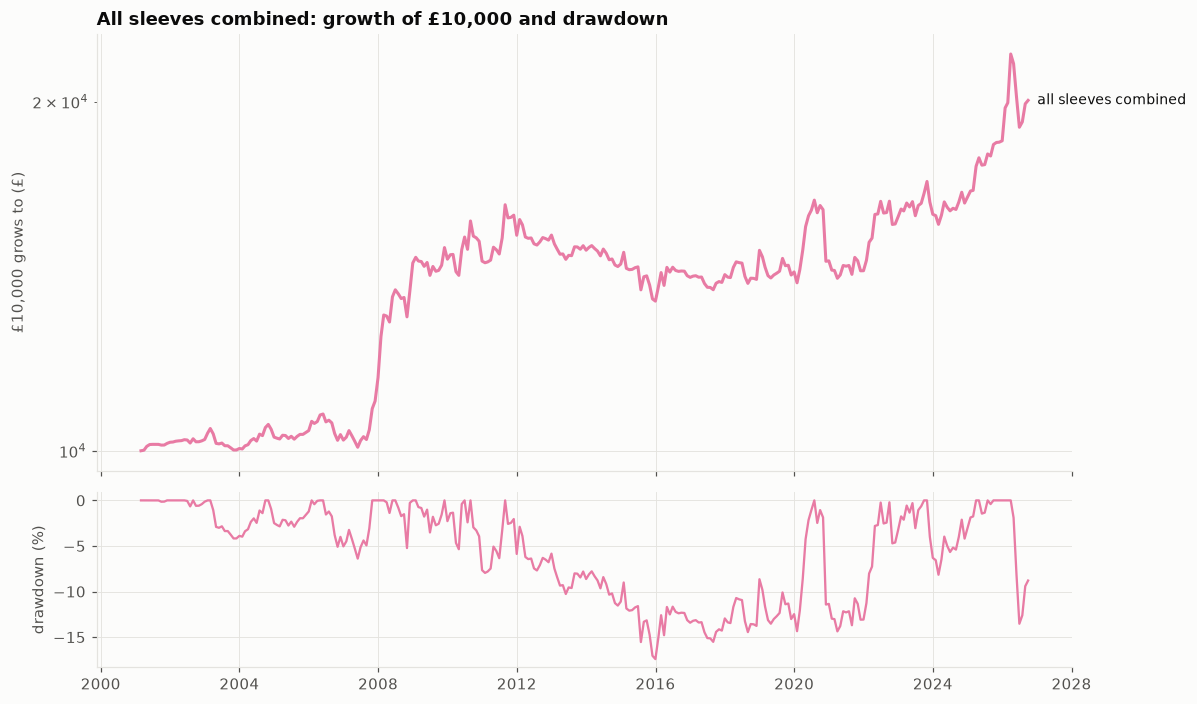

In [3]:
sp.curves({"all sleeves combined": d["sleeves"]}, {"all sleeves combined": sp.COLORS["sleeves"]}, "All sleeves combined: growth of £10,000 and drawdown")

It's not too difficult to notice that the sleeves (combined) seem to be more volatile than the core itself, so the combination of the two seeks to limit the risk from the sleeves, while keeping most of the returns. This is done in 'allocation'.

## The book with and without the sleeves

In [4]:
sp.table("layers_stats.csv").query("layers in ['core + defensive + rebound + overlay', 'book (all five parts)']").set_index(["window", "layers"]).sort_index()

months  sharpe  cagr_pct  vol_pct  max_drawdown_pct  final_gbp_from_10k
window               layers                                                                                                       
2001-05              book (all five parts)                     59   1.422    20.033   10.235            -4.837          24,541.285
                     core + defensive + rebound + overlay      59   1.248    18.952   10.985            -4.727          23,473.659
2006-13              book (all five parts)                     96   1.343    18.390   11.506           -10.640          38,593.491
                     core + defensive + rebound + overlay      96   0.803    12.674   13.270           -20.471          25,976.777
2014-19              book (all five parts)                     72   1.486    14.338    8.989            -7.940          22,342.816
                     core + defensive + rebound + overlay      72   1.419    14.892    9.812           -10.254          23,000.754
2020-26              book (all five parts)                     81   2.004    21.288    8.499            -5.925          36,793.979
                     core + defensive + rebound + overlay      81   0.912    14.393   12.632           -14.918          24,785.389
book 2006-01–2026-09 book (all five parts)                    249   1.557    18.129    9.865           -10.640         317,269.792
                     core + defensive + rebound + overlay     249   0.981    13.870   12.110           -20.471         148,089.092
full 2001-02–2026-09 book (all five parts)                    308   1.533    18.492    9.920           -10.640         778,620.827
                     core + defensive + rebound + overlay     308   1.029    14.827   11.887           -20.471         347,619.291

Notice immediately the seeming 'contradiction' in the 2014-2019 period. That is due to the returns in the above table being relative to the core, and since the sleeves underperformed the core in that period, its Sharpe contribution is negative despite actually increasing the Sharpe of the book. On the whole, the combined sleeves increase the Sharpe of the book in every time period, significantly in 2020-2026 with over half of the Sharpe being from the sleeves, but this trend applies across the board, not just recently.